In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# load the csvs
twsa = pd.read_csv("/home/mgurazada/snowdroughts_thirst/data/twsa_boxplot_data.csv")
swsa = pd.read_csv("/home/mgurazada/snowdroughts_thirst/data/swsa_boxplot_data.csv")
# rsa  = pd.read_csv("/home/mgurazada/snowdroughts_thirst/data/rsa_boxplot_data.csv")

# df = pd.concat([twsa, swsa, rsa], ignore_index=True)
df = pd.concat([twsa, swsa], ignore_index=True)

df.head()

,MAIN_BAS,group,delta_mm,variable
0,1040028970,normal,0.606339,twsa
1,1040028970,low_swe_only,-8.888838,twsa
2,1040028970,high_eto_only,1.224290,twsa
3,1040028970,low_swe_high_eto,-16.926338,twsa
4,1040029430,normal,-0.200179,twsa


In [3]:
# ------------------------------------------------------------
# Create compound-minus-comparison differences from raw boxplot data
# ------------------------------------------------------------

# Keep only the groups needed
keep_groups = [
    "low_swe_high_eto",
    "low_swe_only",
    "high_eto_only",
    "normal"
]

df = df[df["group"].isin(keep_groups)].copy()

# Wide format: one row per basin and variable
df_wide = (
    df.pivot_table(
        index=["MAIN_BAS", "variable"],
        columns="group",
        values="delta_mm",
        aggfunc="mean"
    )
    .reset_index()
)

# Calculate paired basin-level differences
df_wide["comp_minus_normal"] = (
    df_wide["low_swe_high_eto"] - df_wide["normal"]
)

df_wide["comp_minus_snow_only"] = (
    df_wide["low_swe_high_eto"] - df_wide["low_swe_only"]
)

df_wide["comp_minus_demand_only"] = (
    df_wide["low_swe_high_eto"] - df_wide["high_eto_only"]
)

# Convert back to long format for boxplot
df_diff = df_wide.melt(
    id_vars=["MAIN_BAS", "variable"],
    value_vars=[
        "comp_minus_normal",
        "comp_minus_snow_only",
        "comp_minus_demand_only"
    ],
    var_name="comparison",
    value_name="delta_mm"
)

comparison_map = {
    "comp_minus_normal": "Compound − Non-drought",
    "comp_minus_snow_only": "Compound − Snow drought only",
    "comp_minus_demand_only": "Compound − Demand drought only"
}

var_map = {
    "twsa": "TWS",
    "swsa": "SMA"
}

comparison_order = [
    "Compound − Non-drought",
    "Compound − Snow drought only",
    "Compound − Demand drought only"
]

var_order = ["TWS", "SMA"]

df_diff["comparison"] = df_diff["comparison"].map(comparison_map)
df_diff["variable"] = df_diff["variable"].map(var_map)

df_diff["comparison"] = pd.Categorical(
    df_diff["comparison"],
    categories=comparison_order,
    ordered=True
)

df_diff["variable"] = pd.Categorical(
    df_diff["variable"],
    categories=var_order,
    ordered=True
)

df_diff = df_diff.dropna(subset=["delta_mm", "comparison", "variable"]).copy()

df_diff.head()

,MAIN_BAS,variable,comparison,delta_mm
0,1040028970,SMA,Compound − Non-drought,-26.026192
1,1040028970,TWS,Compound − Non-drought,-17.532677
2,1040029430,SMA,Compound − Non-drought,-28.510491
3,1040029430,TWS,Compound − Non-drought,-19.778383
4,1040029700,SMA,Compound − Non-drought,-47.016963


In [4]:
# ------------------------------------------------------------
# Check data
# ------------------------------------------------------------
print(df_diff.head())
print(df_diff.groupby(["variable", "comparison"], observed=True)["delta_mm"].count())

     MAIN_BAS variable              comparison   delta_mm
0  1040028970      SMA  Compound − Non-drought -26.026192
1  1040028970      TWS  Compound − Non-drought -17.532677
2  1040029430      SMA  Compound − Non-drought -28.510491
3  1040029430      TWS  Compound − Non-drought -19.778383
4  1040029700      SMA  Compound − Non-drought -47.016963
variable  comparison                    
TWS       Compound − Non-drought            162
          Compound − Snow drought only      162
          Compound − Demand drought only    162
SMA       Compound − Non-drought            156
          Compound − Snow drought only      156
          Compound − Demand drought only    155
Name: delta_mm, dtype: int64


In [5]:
summary = (
    df_diff.groupby(["variable", "comparison"], observed=True)
    .agg(
        n=("delta_mm", "count"),
        mean=("delta_mm", "mean"),
        median=("delta_mm", "median"),
        q25=("delta_mm", lambda x: np.nanpercentile(x, 25)),
        q75=("delta_mm", lambda x: np.nanpercentile(x, 75)),
        pct_negative=("delta_mm", lambda x: 100 * np.mean(np.asarray(x) < 0)),
    )
    .reset_index()
)

summary

,variable,comparison,n,mean,median,q25,q75,pct_negative
0,TWS,Compound − Non-drought,162,-44.412825,-41.392354,-67.040778,-12.390954,90.740741
1,TWS,Compound − Snow drought only,162,-29.719604,-22.962283,-49.874736,0.760245,72.839506
2,TWS,Compound − Demand drought only,162,-8.019394,-7.343995,-27.520167,16.126071,59.876543
3,SMA,Compound − Non-drought,156,-42.197779,-33.146076,-61.563171,-12.728248,92.307692
4,SMA,Compound − Snow drought only,156,-32.910767,-23.753154,-51.353216,-8.532827,86.538462
5,SMA,Compound − Demand drought only,155,-4.653902,-4.829646,-20.076740,10.457540,58.064516


Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_6.png


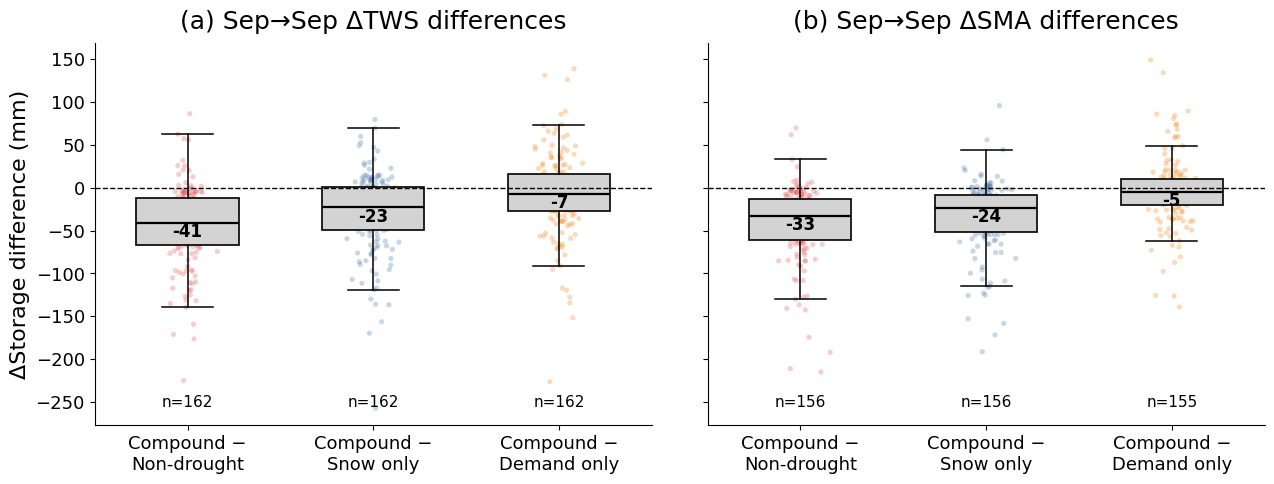

In [6]:
comparison_order = [
    "Compound − Non-drought",
    "Compound − Snow drought only",
    "Compound − Demand drought only"
]

def add_difference_boxplot(ax, data, title, ylabel=None):
    plot_data = [
        data.loc[data["comparison"] == comp, "delta_mm"].dropna().values
        for comp in comparison_order
    ]

    positions = np.arange(1, len(comparison_order) + 1)

    bp = ax.boxplot(
        plot_data,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.6},
        boxprops={"linewidth": 1.2, "edgecolor": "black"},
        whiskerprops={"linewidth": 1.1, "color": "black"},
        capprops={"linewidth": 1.1, "color": "black"},
    )

    for patch in bp["boxes"]:
        patch.set_facecolor("lightgray")

    rng = np.random.default_rng(42)
    point_colors = ["#E45756", "#4C78A8", "#F58518"]

    for x, vals, c in zip(positions, plot_data, point_colors):
        if len(vals) == 0:
            continue

        jitter = rng.normal(0, 0.055, size=len(vals))

        ax.scatter(
            np.full(len(vals), x) + jitter,
            vals,
            s=14,
            alpha=0.30,
            edgecolor="none",
            color=c
        )

    ax.axhline(0, color="black", linewidth=1.0, linestyle="--")

    ax.set_xticks(positions)
    ax.set_xticklabels(
        [
            "Compound −\nNon-drought",
            "Compound −\nSnow only",
            "Compound −\nDemand only",
        ],
        fontsize=13
    )

    ax.set_title(title, fontsize=18, pad=10)

    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=16)

    ax.tick_params(axis="y", labelsize=13)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

    # median labels
    for x, vals in zip(positions, plot_data):
        if len(vals) == 0:
            continue

        med = np.nanmedian(vals)

        ax.text(
            x,
            med,
            f"{med:.0f}",
            ha="center",
            va="bottom" if med >= 0 else "top",
            fontsize=12,
            fontweight="bold"
        )

    # n labels near bottom
    ymin, ymax = ax.get_ylim()
    y_text = ymin + 0.04 * (ymax - ymin)

    for x, vals in zip(positions, plot_data):
        ax.text(
            x,
            y_text,
            f"n={len(vals)}",
            ha="center",
            va="bottom",
            fontsize=11
        )

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5.8),
    sharey=True
)

add_difference_boxplot(
    axes[0],
    df_diff[df_diff["variable"] == "TWS"],
    "(a) Sep→Sep ΔTWS differences",
    ylabel="ΔStorage difference (mm)"
)

add_difference_boxplot(
    axes[1],
    df_diff[df_diff["variable"] == "SMA"],
    "(b) Sep→Sep ΔSMA differences",
    ylabel=None
)

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.22,
    top=0.88,
    wspace=0.10
)

outpath = "/home/mgurazada/snowdroughts_thirst/code/certain/Fig_6.png"

fig.savefig(
    outpath,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print(f"Saved figure to: {outpath}")

plt.show()

In [7]:
comparison_order = [
    "Compound − Non-drought",
    "Compound − Snow drought only",
    "Compound − Demand drought only"
]

var_order = ["TWS", "SMA"]

df_diff["comparison"] = pd.Categorical(
    df_diff["comparison"],
    categories=comparison_order,
    ordered=True
)

df_diff["variable"] = pd.Categorical(
    df_diff["variable"],
    categories=var_order,
    ordered=True
)

In [8]:
# ------------------------------------------------------------
# Bootstrap test: median basin-level difference vs zero
# ------------------------------------------------------------

def bootstrap_median_ci(vals, n_boot=10000, ci=95, seed=42):
    vals = np.asarray(vals, dtype=float)
    vals = vals[np.isfinite(vals)]

    if len(vals) == 0:
        return np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)

    boot_medians = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(
            vals,
            size=len(vals),
            replace=True
        )
        boot_medians[i] = np.median(sample)

    alpha = (100 - ci) / 2

    ci_low = np.percentile(
        boot_medians,
        alpha
    )

    ci_high = np.percentile(
        boot_medians,
        100 - alpha
    )

    median = np.median(vals)

    return median, ci_low, ci_high


# ------------------------------------------------------------
# Calculate bootstrap confidence intervals for each comparison
# ------------------------------------------------------------

test_rows = []

for comp in comparison_order:
    for var in var_order:

        vals = df_diff.loc[
            (df_diff["comparison"] == comp) &
            (df_diff["variable"] == var),
            "delta_mm"
        ].dropna().values

        if len(vals) > 0:

            # Bootstrap 95% CI for median
            med, ci_low, ci_high = bootstrap_median_ci(
                vals,
                n_boot=10000,
                ci=95,
                seed=42
            )

            # Other descriptive statistics
            q25 = np.nanpercentile(vals, 25)
            q75 = np.nanpercentile(vals, 75)
            pct_negative = 100 * np.mean(vals < 0)

            # Significant if 95% bootstrap CI excludes zero
            significant = (
                (ci_high < 0) or
                (ci_low > 0)
            )

        else:

            med = np.nan
            q25 = np.nan
            q75 = np.nan
            pct_negative = np.nan
            ci_low = np.nan
            ci_high = np.nan
            significant = False

        test_rows.append({
            "comparison": comp,
            "variable": var,
            "n": len(vals),
            "median": med,
            "q25": q25,
            "q75": q75,
            "pct_negative": pct_negative,
            "bootstrap_ci_low": ci_low,
            "bootstrap_ci_high": ci_high,
            "significant": significant
        })


# ------------------------------------------------------------
# Create summary dataframe
# ------------------------------------------------------------

test_summary = pd.DataFrame(test_rows)


# ------------------------------------------------------------
# Add significance stars
# * = 95% bootstrap CI excludes zero
# ------------------------------------------------------------

test_summary["stars"] = np.where(
    test_summary["significant"],
    "*",
    ""
)


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

test_summary

,comparison,variable,n,median,q25,q75,pct_negative,bootstrap_ci_low,bootstrap_ci_high,significant,stars
0,Compound − Non-drought,TWS,162,-41.392354,-67.040778,-12.390954,90.740741,-47.887361,-31.426271,True,*
1,Compound − Non-drought,SMA,156,-33.146076,-61.563171,-12.728248,92.307692,-39.184891,-28.826885,True,*
2,Compound − Snow drought only,TWS,162,-22.962283,-49.874736,0.760245,72.839506,-31.924929,-16.160473,True,*
3,Compound − Snow drought only,SMA,156,-23.753154,-51.353216,-8.532827,86.538462,-29.884115,-19.112931,True,*
4,Compound − Demand drought only,TWS,162,-7.343995,-27.520167,16.126071,59.876543,-12.154374,-1.469917,True,*
5,Compound − Demand drought only,SMA,155,-4.829646,-20.076740,10.457540,58.064516,-9.747995,-0.359058,True,*


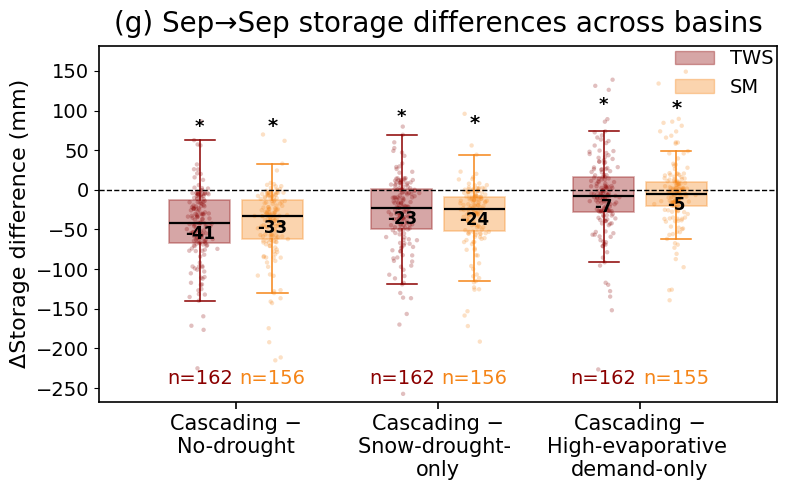

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# Grouped boxplot: TWS and SMA side by side for each comparison
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

# x positions for the 3 comparison groups
group_centers = np.array([1, 2, 3])

# offsets so TWS and SMA appear side by side
offset = 0.18
pos_tws = group_centers - offset
pos_sma = group_centers + offset

width = 0.30

# colors
colors = {
    "TWS": "#8B0000",
    "SMA": "#F58518"
}

# comparison order
comparison_order = [
    "Compound − Non-drought",
    "Compound − Snow drought only",
    "Compound − Demand drought only"
]

# ------------------------------------------------------------
# Collect data
# ------------------------------------------------------------

tws_data = [
    df_diff.loc[
        (df_diff["comparison"] == comp) & (df_diff["variable"] == "TWS"),
        "delta_mm"
    ].dropna().values
    for comp in comparison_order
]

sma_data = [
    df_diff.loc[
        (df_diff["comparison"] == comp) & (df_diff["variable"] == "SMA"),
        "delta_mm"
    ].dropna().values
    for comp in comparison_order
]

# ------------------------------------------------------------
# Boxplots
# ------------------------------------------------------------

bp_tws = ax.boxplot(
    tws_data,
    positions=pos_tws,
    widths=width,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 1.6},
    boxprops={"linewidth": 1.2},
    whiskerprops={"linewidth": 1.1},
    capprops={"linewidth": 1.1},
)

bp_sma = ax.boxplot(
    sma_data,
    positions=pos_sma,
    widths=width,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 1.6},
    boxprops={"linewidth": 1.2},
    whiskerprops={"linewidth": 1.1},
    capprops={"linewidth": 1.1},
)

# ------------------------------------------------------------
# Assign box colors
# ------------------------------------------------------------

for patch in bp_tws["boxes"]:
    patch.set_facecolor(colors["TWS"])
    patch.set_alpha(0.35)
    patch.set_edgecolor(colors["TWS"])

for patch in bp_sma["boxes"]:
    patch.set_facecolor(colors["SMA"])
    patch.set_alpha(0.35)
    patch.set_edgecolor(colors["SMA"])

# color whiskers and caps to match
for whisker in bp_tws["whiskers"]:
    whisker.set_color(colors["TWS"])

for cap in bp_tws["caps"]:
    cap.set_color(colors["TWS"])

for whisker in bp_sma["whiskers"]:
    whisker.set_color(colors["SMA"])

for cap in bp_sma["caps"]:
    cap.set_color(colors["SMA"])

# medians black
for median in bp_tws["medians"]:
    median.set_color("black")
    median.set_linewidth(1.6)

for median in bp_sma["medians"]:
    median.set_color("black")
    median.set_linewidth(1.6)

# ------------------------------------------------------------
# Jittered points
# ------------------------------------------------------------

rng = np.random.default_rng(42)

for x, vals in zip(pos_tws, tws_data):
    jitter = rng.normal(0, 0.03, size=len(vals))
    ax.scatter(
        np.full(len(vals), x) + jitter,
        vals,
        s=10,
        alpha=0.25,
        color=colors["TWS"],
        edgecolor="none"
    )

for x, vals in zip(pos_sma, sma_data):
    jitter = rng.normal(0, 0.03, size=len(vals))
    ax.scatter(
        np.full(len(vals), x) + jitter,
        vals,
        s=10,
        alpha=0.25,
        color=colors["SMA"],
        edgecolor="none"
    )

# ------------------------------------------------------------
# Median labels
# ------------------------------------------------------------

median_offset = 3  # mm; increase/decrease as needed

for x, vals in zip(pos_tws, tws_data):
    if len(vals) > 0:
        med = np.nanmedian(vals)
        ax.text(
            x,
            med - median_offset,
            f"{med:.0f}",
            ha="center",
            va="top",
            fontsize=12,
            fontweight="bold",
            color="black"
        )

for x, vals in zip(pos_sma, sma_data):
    if len(vals) > 0:
        med = np.nanmedian(vals)
        ax.text(
            x,
            med - median_offset,
            f"{med:.0f}",
            ha="center",
            va="top",
            fontsize=12,
            fontweight="bold",
            color="black"
        )

# ------------------------------------------------------------
# Mark groups whose 95% bootstrap CI for the median excludes zero
# ------------------------------------------------------------

star_y_offset = 80

for x, comp in zip(pos_tws, comparison_order):
    row = test_summary[
        (test_summary["comparison"] == comp) &
        (test_summary["variable"] == "TWS")
    ].iloc[0]

    vals = df_diff.loc[
        (df_diff["comparison"] == comp) &
        (df_diff["variable"] == "TWS"),
        "delta_mm"
    ].dropna().values

    if len(vals) > 0:
        y_star = np.nanpercentile(vals, 75) + star_y_offset

        ax.text(
            x,
            y_star,
            row["stars"],
            ha="center",
            va="bottom",
            fontsize=13,
            fontweight="bold",
            color="black"
        )

for x, comp in zip(pos_sma, comparison_order):
    row = test_summary[
        (test_summary["comparison"] == comp) &
        (test_summary["variable"] == "SMA")
    ].iloc[0]

    vals = df_diff.loc[
        (df_diff["comparison"] == comp) &
        (df_diff["variable"] == "SMA"),
        "delta_mm"
    ].dropna().values

    if len(vals) > 0:
        y_star = np.nanpercentile(vals, 75) + star_y_offset

        ax.text(
            x,
            y_star,
            row["stars"],
            ha="center",
            va="bottom",
            fontsize=14,
            fontweight="bold",
            color="black"
        )

        
# ------------------------------------------------------------
# n labels and tighter y-limits
# ------------------------------------------------------------

all_vals = np.concatenate(
    [v for v in tws_data + sma_data if len(v) > 0]
)

ymin_all = np.nanmin(all_vals)
ymax_all = np.nanmax(all_vals)

# Tighter y-limits to reduce white space
ax.set_ylim(
    ymin_all - 10,
    ymax_all + 0.08 * (ymax_all - ymin_all)
)

ymin, ymax = ax.get_ylim()
y_text = ymin + 0.04 * (ymax - ymin)

# Put TWS and SMA n labels on the same y-level
for x, vals in zip(pos_tws, tws_data):
    ax.text(
        x,
        y_text,
        f"n={len(vals)}",
        ha="center",
        va="bottom",
        fontsize=14,
        color=colors["TWS"]
    )

for x, vals in zip(pos_sma, sma_data):
    ax.text(
        x,
        y_text,
        f"n={len(vals)}",
        ha="center",
        va="bottom",
        fontsize=14,
        color=colors["SMA"]
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(group_centers)

ax.set_xticklabels(
    [
        "Cascading −\nNo-drought",
        "Cascading −\nSnow-drought- \nonly",
        "Cascading −\nHigh-evaporative \ndemand-only"
    ],
    fontsize=15
)

ax.set_ylabel(
    "ΔStorage difference (mm)",
    fontsize=16
)

ax.set_title(
    "(g) Sep→Sep storage differences across basins",
    fontsize=20,
    pad=10
)

ax.tick_params(
    axis="y",
    labelsize=14
)

ax.tick_params(
    axis="x",
    width=1.2,
    length=5,
    colors="black"
)

# Full black box around panel
for side in ["top", "bottom", "left", "right"]:
    ax.spines[side].set_visible(True)
    ax.spines[side].set_color("black")
    ax.spines[side].set_linewidth(1.2)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor=colors["TWS"],
        edgecolor=colors["TWS"],
        alpha=0.35,
        label="TWS"
    ),
    Patch(
        facecolor=colors["SMA"],
        edgecolor=colors["SMA"],
        alpha=0.35,
        label="SM"
    ),
]

ax.legend(
    handles=legend_handles,
    frameon=False,
    fontsize=14,
    loc="upper right",
    bbox_to_anchor=(1.02, 1.04)
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    "/home/mgurazada/snowdroughts_thirst/code/certain/Fig_6.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()